# Library

In [30]:
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt

# from sklearn.datasets import load_boston
# from fairlearn.datasets import fetch_boston

from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression, LinearRegression, Lasso, Ridge

from sklearn.metrics import accuracy_score
from sklearn.metrics import mean_squared_error

import warnings
warnings.filterwarnings('ignore')

In [31]:
# generate synthetic data
np.random.seed(0)

X = np.random.rand(100,1)
y = 2*X + 1 + 0.1 * np.random.rand(100,1)
# y = pow(X,3)
# y = 

# split
X_train, X_test, y_train, y_test = train_test_split(
X,
y,
test_size=0.2,
random_state=42
)

# display(X_train.shape,X_test.shape)
# display(X,y)

In [32]:
# 
alphas = np.logspace(-2,0.5,200)

lasso_coefs = []
ridge_coefs = []
lr_coefs = []

for alpha in alphas:
    #lasso
    lasso = Lasso(alpha=alpha)
    lasso.fit(X_train,y_train)
    lasso_coefs.append(lasso.coef_[0])

    #ridge
    ridge = Ridge(alpha=alpha)
    ridge.fit(X_train,y_train)
    ridge_coefs.append(ridge.coef_[0])

    #lr
    lr = LinearRegression()
    lr.fit(X_train,y_train)
    lr_coefs.append(lr.coef_[0])

# make prediction
y_lasso = lasso.predict(y_test)
y_ridge = ridge.predict(y_test)
y_lr = lr.predict(y_test)

# calculate mse for each model
mse_lasso = mean_squared_error(y_test,y_lasso)
mse_ridge = mean_squared_error(y_test,y_ridge)
mse_lr = mean_squared_error(y_test,y_lr)


In [33]:
display(mse_lasso,mse_ridge,mse_lr)

0.23474747707920476

4.63059219512305

10.172892320994979

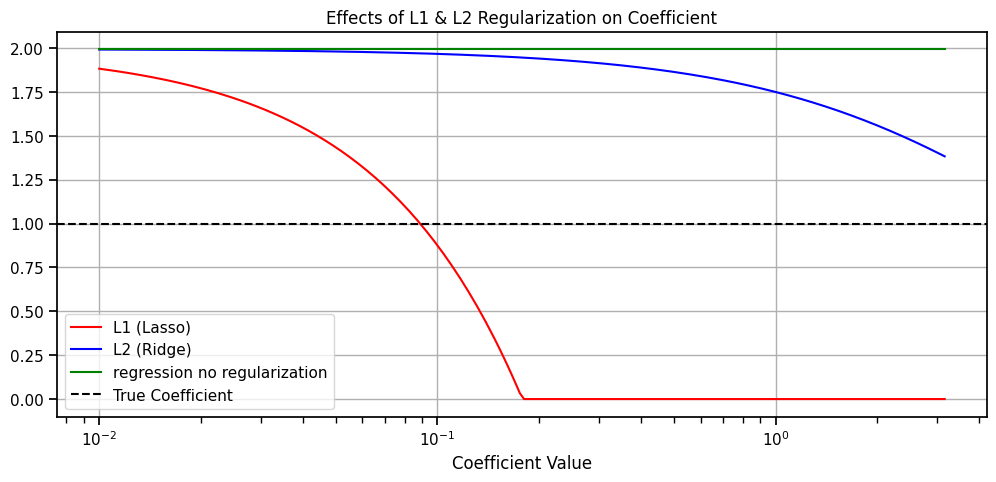

In [34]:
# plot
plt.figure(figsize=(12,5))
plt.plot(alphas,lasso_coefs,label='L1 (Lasso)',color='r')
plt.plot(alphas,ridge_coefs,label='L2 (Ridge)',color='b')
plt.plot(alphas,lr_coefs,label='regression no regularization',color='g')
plt.axhline(1, color='k', linestyle='--',label='True Coefficient')

# scale
plt.xscale('log')
plt.axis('tight')

# set plot labels
plt.xlabel('Lambda (Regularization Length)')
plt.xlabel('Coefficient Value')
plt.title('Effects of L1 & L2 Regularization on Coefficient')
plt.legend()

plt.grid()
plt.show()

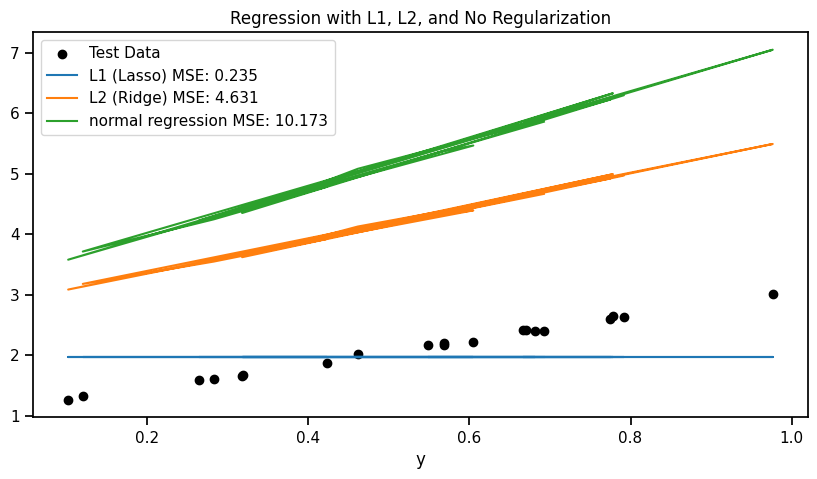

In [35]:
# plot prediction for each model
plt.figure(figsize=(10,5))

# plot the data points
plt.scatter(X_test,y_test,label='Test Data',color='black')

# plot the model prediction
plt.plot(X_test, y_lasso, label=f'L1 (Lasso) MSE: {mse_lasso:.3f}')
plt.plot(X_test, y_ridge, label=f'L2 (Ridge) MSE: {mse_ridge:.3f}')
plt.plot(X_test, y_lr, label=f'normal regression MSE: {mse_lr:.3f}')

# plot label and title
plt.xlabel('X')
plt.xlabel('y')
plt.title('Regression with L1, L2, and No Regularization')
plt.legend()

# Model Complexity : Linear Model Regression

> ## Data

Column name | Description

CRIM | per capita crime rate by town

ZN | proportion of residential land zoned for lots over 25,000 sq.ft.

INDUS | proportion of non-retail business acres per town

CHAS | Charles River dummy variable (= 1 if tract bounds river; 0 otherwise)

NOX | nitric oxides concentration (parts per 10 million)

RM | average number of rooms per dwelling

AGE | proportion of owner-occupied units built prior to 1940

DIS | weighted distances to five Boston employment centers

RAD | index of accessibility to radial highways

TAX | full-value property-tax rate per $10,000

PTRATIO | pupil-teacher ratio by town

B | 1000(Bk - 0.63)^2 where Bk is the proportion of Black people by town

LSTAT | % lower status of the population

MEDV | Median value of owner-occupied homes in $1000’s

In [36]:
boston = pd.read_csv('boston.csv')


In [37]:
boston.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     506 non-null    float64
 1   ZN       506 non-null    float64
 2   INDUS    506 non-null    float64
 3   CHAS     506 non-null    int64  
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      506 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    int64  
 9   TAX      506 non-null    float64
 10  PTRATIO  506 non-null    float64
 11  B        506 non-null    float64
 12  LSTAT    506 non-null    float64
 13  MEDV     506 non-null    float64
dtypes: float64(12), int64(2)
memory usage: 55.5 KB


In [38]:
boston.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2


In [39]:
# feature selection
X = boston.drop(['MEDV'],axis=1)
y = boston['MEDV']
display(X,y)

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33
...,...,...,...,...,...,...,...,...,...,...,...,...,...
501,0.06263,0.0,11.93,0,0.573,6.593,69.1,2.4786,1,273.0,21.0,391.99,9.67
502,0.04527,0.0,11.93,0,0.573,6.120,76.7,2.2875,1,273.0,21.0,396.90,9.08
503,0.06076,0.0,11.93,0,0.573,6.976,91.0,2.1675,1,273.0,21.0,396.90,5.64
504,0.10959,0.0,11.93,0,0.573,6.794,89.3,2.3889,1,273.0,21.0,393.45,6.48


0      24.0
1      21.6
2      34.7
3      33.4
4      36.2
       ... 
501    22.4
502    20.6
503    23.9
504    22.0
505    11.9
Name: MEDV, Length: 506, dtype: float64

> ## Data Splitting

In [40]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.2, 
    random_state = 1899) # make the result consistent

> ## Ridge Regression

In [41]:
hyperparam_c = [100000, 10000, 1000, 100, 10, 1, 0.1, 0.001]
testing_mse = []
training_mse = []
score = 0

for i in hyperparam_c:
  ridgereg = Ridge(alpha = i)
  ridgereg.fit(X_train,y_train)

  y_predict_train = ridgereg.predict(X_train)
  training_mse.append(mean_squared_error(y_train,y_predict_train))

  y_predict_test = ridgereg.predict(X_test)
  mse_score = mean_squared_error(y_test,y_predict_test)
  testing_mse.append(mse_score)

  if score > -mse_score:
    score = mse_score
    best_c = i

In [42]:
# create dataframe
df_k = pd.DataFrame(
    {
        'hyperparam_c': hyperparam_c,
        'training_mse': training_mse,
        'testing_mse': testing_mse
    }
)
df_k

,hyperparam_c,training_mse,testing_mse
0,100000.000,55.545175,54.032576
1,10000.000,38.339391,36.904718
2,1000.000,27.296486,31.760613
3,100.000,22.605112,30.587073
4,10.000,21.239138,30.690713
5,1.000,20.799339,29.635100
6,0.100,20.668096,28.901242
7,0.001,20.664301,28.778403


In [43]:
# re-pivot and ranking
df_melted = pd.melt(df_k, id_vars=["hyperparam_c"], value_vars=["training_mse", "testing_mse"], var_name="attribute", value_name="value")
# df_melted['cat_index'] = [0,1,2,3,4,5,6,7,0,1,2,3,4,5,6,7] # re-scale hyperparam_c
df_melted["RANK"] = df_melted.groupby("attribute")["hyperparam_c"].rank(method="first", ascending=False) # indexing by attribute, hyperparam_c
df_melted

,hyperparam_c,attribute,value,RANK
0,100000.000,training_mse,55.545175,1.0
1,10000.000,training_mse,38.339391,2.0
2,1000.000,training_mse,27.296486,3.0
3,100.000,training_mse,22.605112,4.0
4,10.000,training_mse,21.239138,5.0
5,1.000,training_mse,20.799339,6.0
6,0.100,training_mse,20.668096,7.0
7,0.001,training_mse,20.664301,8.0
8,100000.000,testing_mse,54.032576,1.0
9,10000.000,testing_mse,36.904718,2.0


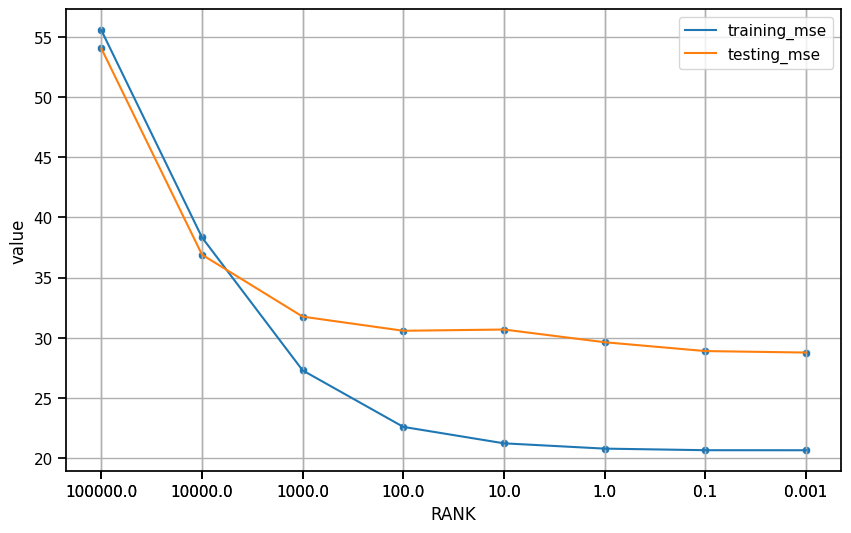

In [44]:
# plot
plt.figure(figsize=(10,6))
sns.set_context('notebook',font_scale=1)
ax = sns.lineplot(data=df_melted,x='RANK',y='value',hue='attribute')
sns.scatterplot(data=df_melted,x='RANK',y='value')
ax.set_xticks(df_melted['RANK'],df_melted['hyperparam_c'])
plt.grid()

In [45]:
print('best c:', best_c)
print('mse:', score)

best c: 0.001
mse: 28.778402778052925


In [46]:
ridgereg = Ridge(alpha=best_c) 
ridgereg.fit(X_train, y_train) 

Ridge(alpha=0.001)

In [47]:
y_reg_train = ridgereg.predict(X_train)
y_reg_test = ridgereg.predict(X_test)

In [48]:
coef_ridgereg = pd.DataFrame({
    'feature_names':list(X),
    'feature coef':ridgereg.coef_
})

In [49]:
coef_ridgereg

,feature_names,feature coef
0,CRIM,-0.123098
1,ZN,0.027489
2,INDUS,0.040234
3,CHAS,1.676822
4,NOX,-14.800396
5,RM,4.324093
6,AGE,0.002115
7,DIS,-1.253837
8,RAD,0.328548
9,TAX,-0.014321


In [50]:
print('mse train:',mean_squared_error(y_train,y_reg_train))
print('mse test:',mean_squared_error(y_test,y_reg_test))

mse train: 20.664301374310284
mse test: 28.778402778052925


1. When alpha set to high value the model is very underfitting becasue both mse in training set and test set are large and it also means that the model is too simple
1. lower alpha can decrese the mse for both training set  and test set until mse in training slighly lower than mse in test set
1. the best alpha for this case is 0.001 with 28.778 mse

> ## Lasso Regression

In [51]:
hyperparam_c = [100000, 10000, 1000, 100, 10, 1, 0.1, 0.001]
testing_mse = []
training_mse = []
score = 0

for i in hyperparam_c:
  lassoreg = Lasso(alpha = i)
  lassoreg.fit(X_train,y_train)

  y_predict_train = lassoreg.predict(X_train)
  training_mse.append(mean_squared_error(y_train,y_predict_train))

  y_predict_test = lassoreg.predict(X_test)
  mse_score = mean_squared_error(y_test,y_predict_test)
  testing_mse.append(mse_score)

  if score > -mse_score:
    score = mse_score
    best_c = i

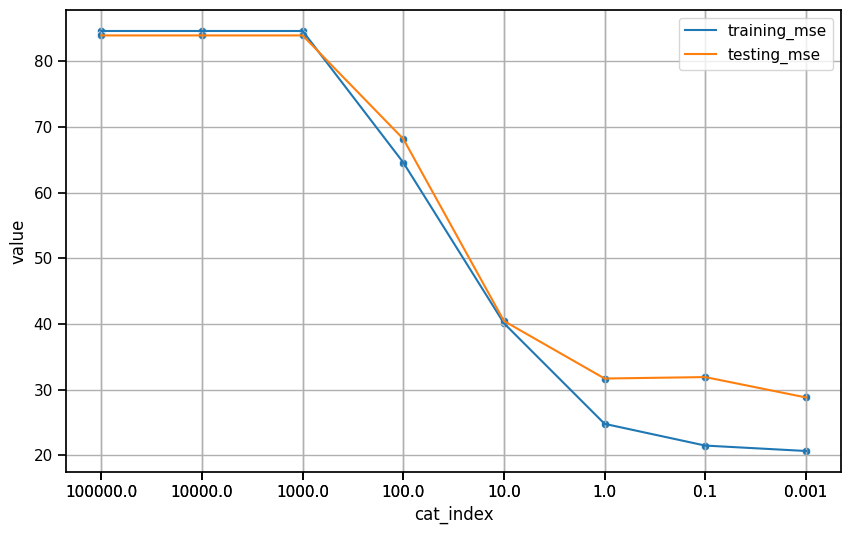

In [52]:
df_k = pd.DataFrame(
    {
        'hyperparam_c': hyperparam_c,
        'training_mse': training_mse,
        'testing_mse': testing_mse
    }
)
df_k

df_melted = pd.melt(df_k, id_vars=["hyperparam_c"], value_vars=["training_mse", "testing_mse"], var_name="attribute", value_name="value")
df_melted['cat_index'] = [0,1,2,3,4,5,6,7,0,1,2,3,4,5,6,7] # re-scale hyperparam_c
df_melted

# plot
plt.figure(figsize=(10,6))
sns.set_context('notebook',font_scale=1)
ax = sns.lineplot(data=df_melted,x='cat_index',y='value',hue='attribute')
sns.scatterplot(data=df_melted,x='cat_index',y='value')
ax.set_xticks(df_melted['cat_index'],df_melted['hyperparam_c'])
plt.grid()

In [53]:
print('best c:', best_c)
print('mse:', score)

best c: 0.001
mse: 28.820511284098718


In [54]:
lassoreg = Lasso(alpha=best_c) 
lassoreg.fit(X_train, y_train) 

Lasso(alpha=0.001)

In [55]:
y_reg_train = lassoreg.predict(X_train)
y_reg_test = lassoreg.predict(X_test)

In [56]:
coef_lassoreg = pd.DataFrame({
    'feature_names':list(X),
    'feature coef':lassoreg.coef_
})

In [57]:
coef_lassoreg

,feature_names,feature coef
0,CRIM,-0.122920
1,ZN,0.027515
2,INDUS,0.038746
3,CHAS,1.655566
4,NOX,-14.470963
5,RM,4.324770
6,AGE,0.001868
7,DIS,-1.248666
8,RAD,0.327883
9,TAX,-0.014347


In [58]:
print('mse train:',mean_squared_error(y_train,y_reg_train))
print('mse test:',mean_squared_error(y_test,y_reg_test))

mse train: 20.66467425317308
mse test: 28.820511284098718


1. When alpha set to high value the model is very underfitting becasue both mse in training set and test set are large and it also means that the model is too simple
1. lower alpha can decrease the mse for both training set  and test set until mse in training slighly lower than mse in test set
1. the best alpha for this case is 0.001 with 28.8205 mse